In [10]:
# 都道府県データから考える外国人観光客の受け入れ先
**氏名：** 吉野健人

**依頼元：** 地域の観光協会  
**読み手：** 観光客を増やしたい自治体・観光施設の担当者  
**調べたい問い：** 外国人の宿泊者が多い都道府県はどこか。また、外国人宿泊者の割合が高い地域にはどのような特徴があるか。

## 1. 調査の目的
地域の観光協会のインターンとして、都道府県ごとの宿泊データを比べます。外国人の宿泊者数が多い地域と、宿泊者全体に占める外国人の割合が高い地域を調べ、観光客を呼び込むための参考にします。

この分析では、人数の多さだけでなく「外国人延べ宿泊者数 ÷ 延べ宿泊者数 × 100」で割合も計算します。人数は地域の規模に影響されるため、割合も見ることで違った特徴を見つけられます。


SyntaxError: invalid character '：' (U+FF1A) (2774084006.py, line 2)

## 2. データの読み込み
授業で配布された `japan.csv` を使います。今回はPython標準の `csv` モジュールを使って読み込みます。pandasを使わなくても、リスト・辞書・forループで集計できます。CSVファイルはNotebookと同じフォルダに置いてください。


In [11]:
import csv

with open("japan.csv", "r", encoding="utf-8-sig", newline="") as f:
    reader = csv.DictReader(f)
    data = list(reader)

print("都道府県の数:", len(data))
print("列名:", reader.fieldnames[:10], "...") 
print("最初の3件:")
for row in data[:3]:
    print(row["都道府県"], row["延べ宿泊者数"], row["外国人延べ宿泊者数"])


都道府県の数: 47
列名: ['Prefecture', '都道府県', '総人口', '日本人人口', '15歳未満人口', '15～64歳人口', '65歳以上人口', '外国人人口', '出生数', '合計特殊出生率'] ...
最初の3件:
北海道 24664930 741410
青森県 3440670 28190
岩手県 4268160 22640


## 3. データの確認
今回は47都道府県のデータが入っていることを確認します。分析に使う3つの項目は、都道府県名、延べ宿泊者数、外国人延べ宿泊者数です。

In [12]:
# 数値データに変換して、確認する
total_stays = []
foreign_stays = []

for row in data:
    total_stays.append(int(row["延べ宿泊者数"]))
    foreign_stays.append(int(row["外国人延べ宿泊者数"]))

print("都道府県数:", len(data))
print("延べ宿泊者数の最小値:", min(total_stays))
print("延べ宿泊者数の最大値:", max(total_stays))
print("外国人延べ宿泊者数の最小値:", min(foreign_stays))
print("外国人延べ宿泊者数の最大値:", max(foreign_stays))


都道府県数: 47
延べ宿泊者数の最小値: 1424610
延べ宿泊者数の最大値: 50915670
外国人延べ宿泊者数の最小値: 6610
外国人延べ宿泊者数の最大値: 5627190


## 4. forループで外国人宿泊者数と割合を計算
各都道府県について、外国人延べ宿泊者数を合計宿泊者数で割り、割合を計算します。計算結果は辞書のリストにまとめます。

In [13]:
results = []

for row in data:
    prefecture = row["都道府県"]
    total = int(row["延べ宿泊者数"])
    foreign = int(row["外国人延べ宿泊者数"])

    if total > 0:
        rate = foreign / total * 100
    else:
        rate = 0

    results.append({
        "都道府県": prefecture,
        "延べ宿泊者数": total,
        "外国人延べ宿泊者数": foreign,
        "外国人宿泊割合(%)": rate
    })

print("計算した都道府県数:", len(results))


計算した都道府県数: 47


## 5. 外国人延べ宿泊者数ランキング
外国人の延べ宿泊者数が多い順に並べ、上位10都道府県を表示します。

In [6]:
ranking = sorted(results, key=lambda x: x["外国人延べ宿泊者数"], reverse=True)

print("【外国人延べ宿泊者数 上位10都道府県】")
print(f'{"順位":<4} {"都道府県":<8} {"外国人延べ宿泊者数":>18}')
for i, row in enumerate(ranking[:10], start=1):
    print(f'{i:<4} {row["都道府県"]:<8} {row["外国人延べ宿泊者数"]:>18,}')


【外国人延べ宿泊者数 上位10都道府県】
順位   都道府県              外国人延べ宿泊者数


## 6. 外国人宿泊割合ランキング
次に、宿泊者全体に占める外国人の割合が高い順に並べます。人数ランキングと順位が違うかを比べます。

In [20]:
rate_ranking = sorted(results, key=lambda x: x["外国人宿泊割合(%)"], reverse=True)

print("【外国人宿泊割合 上位10都道府県】")
print(f'{"順位":<4} {"都道府県":<8} {"外国人宿泊割合":>14}')
for i, row in enumerate(rate_ranking[:10], start=1):
    print(f'{i:<4} {row["都道府県"]:<8} {row["外国人宿泊割合(%)"]:>13.2f}%')


【外国人宿泊割合 上位10都道府県】
順位   都道府県            外国人宿泊割合
1    東京都              11.05%
2    大阪府               6.72%
3    京都府               6.12%
4    福岡県               4.22%
5    千葉県               3.76%
6    北海道               3.01%
7    沖縄県               2.95%
8    神奈川県              2.79%
9    大分県               2.70%
10   山梨県               2.68%


## 7. グラフで比較
外国人延べ宿泊者数の上位10都道府県を棒グラフにします。ランキング表と合わせて見ることで、地域ごとの差を確認しやすくします。

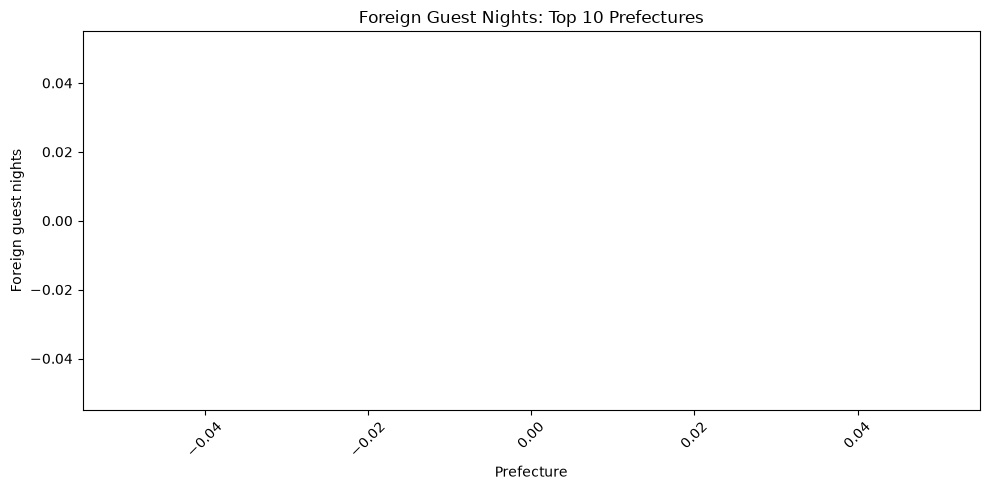

In [21]:
import matplotlib.pyplot as plt

top10 = ranking[:10]
names = [row["Prefecture"] for row in top10]
values = [row["外国人延べ宿泊者数"] for row in top10]

plt.figure(figsize=(10, 5))
plt.bar(names, values)
plt.title("Foreign Guest Nights: Top 10 Prefectures")
plt.xlabel("Prefecture")
plt.ylabel("Foreign guest nights")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 8. 分析して分かったこと
外国人延べ宿泊者数のランキングでは、東京都が最も多く、大阪府、京都府が続きます。一方、外国人宿泊割合も東京都、大阪府、京都府が上位になっています。

ただし、宿泊者数は観光地の数や交通の便利さ、地域の人口・施設規模など、さまざまな要因に影響されます。このデータだけで、外国人観光客がその地域を選ぶ理由まで断定することはできません。


In [16]:
# 上位3都道府県を数字で確認し、レポートの説明に使う
print("外国人延べ宿泊者数 上位3都道府県")
for row in ranking[:3]:
    print(row["都道府県"], f'{row["外国人延べ宿泊者数"]:,} 人泊')

print("\n外国人宿泊割合 上位3都道府県")
for row in rate_ranking[:3]:
    print(row["都道府県"], f'{row["外国人宿泊割合(%)"]:.2f}%')


外国人延べ宿泊者数 上位3都道府県

外国人宿泊割合 上位3都道府県
東京都 11.05%
大阪府 6.72%
京都府 6.12%


In [17]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----- ---------------------------------- 1.3/9.5 MB 11.5 MB/s eta 0:00:01
   ----

## 9. 組織への提案
観光協会には、外国人宿泊者数が多い地域の観光案内や情報発信の方法を参考にしながら、地域の魅力を外国語で紹介することを提案します。また、人数だけでなく外国人宿泊割合も毎年確認し、観光客を増やす取り組みの効果を比べるとよいと思います。

特に、外国人宿泊者数が上位の地域と自分たちの地域を比べ、交通案内、宿泊施設、観光情報の発信など、足りない点を探すことが大切です。今回のデータだけでは原因を特定できないため、次の段階では観光客へのアンケートや観光施設のデータも合わせて調べると、より具体的な対策につながります。

## 10. データについて
- 使用データ：授業で配布された `japan.csv`
- 対象：47都道府県
- 使用項目：都道府県、延べ宿泊者数、外国人延べ宿泊者数
- 方法：Python標準の `csv` モジュール、リスト、辞書、forループ、if文、sorted関数、matplotlib
- 注意：CSV内に調査年や出典の詳細が記載されていないため、このNotebookでは授業配布データとして扱っています。提出時に授業資料で出典・調査年が分かれば追記してください。
